# Benign vs Malignant Ultrasound Image Classification

**Goal:** compare a baseline ML model with an improved deep-learning model using the **exact same held-out test images**. The notebook is designed for the uploaded `Datasets.zip` structure:

```text
Datasets/
  benign/
  malignant/
  normal/   # ignored if present
```

Only **benign** and **malignant** images are used. Do not use the test set for model selection or threshold tuning. High accuracy cannot be guaranteed; report all metrics, especially malignant recall and PR-AUC because the classes are imbalanced.



## 1. Setup and extract the dataset

In [ ]:
# If running in Google Colab, upload Datasets.zip when prompted.
# If the ZIP is already in the runtime at /mnt/data/Datasets (2).zip, this cell uses it.
from pathlib import Path
import os, zipfile, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

possible_zips = [
    Path("/mnt/data/Datasets (2).zip"),
    Path("/content/Datasets.zip"),
    Path("Datasets.zip")
]
zip_path = next((p for p in possible_zips if p.exists()), None)

if zip_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        zip_path = Path(next(iter(uploaded.keys())))
    except Exception as e:
        raise FileNotFoundError("Put Datasets.zip in the runtime or upload it in Colab.") from e

extract_dir = Path("/content/dataset_extracted") if Path("/content").exists() else Path("./dataset_extracted")
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(extract_dir)

# Find the directory that contains benign/ and malignant/
data_dir = None
for p in [extract_dir, *extract_dir.rglob("*")]:
    if p.is_dir() and (p / "benign").is_dir() and (p / "malignant").is_dir():
        data_dir = p
        break

if data_dir is None:
    raise FileNotFoundError("Could not find folders named benign and malignant after extraction.")

print("Dataset folder:", data_dir)


Saving Datasets (2).zip to Datasets (2).zip
Dataset folder: /content/dataset_extracted/Datasets


## 2. Build a binary dataset

label
malignant    2209
benign        390
Name: count, dtype: int64


,path,label
0,/content/dataset_extracted/Datasets/benign/ben...,benign
1,/content/dataset_extracted/Datasets/benign/116...,benign
2,/content/dataset_extracted/Datasets/benign/59_...,benign
3,/content/dataset_extracted/Datasets/benign/92_...,benign
4,/content/dataset_extracted/Datasets/benign/167...,benign


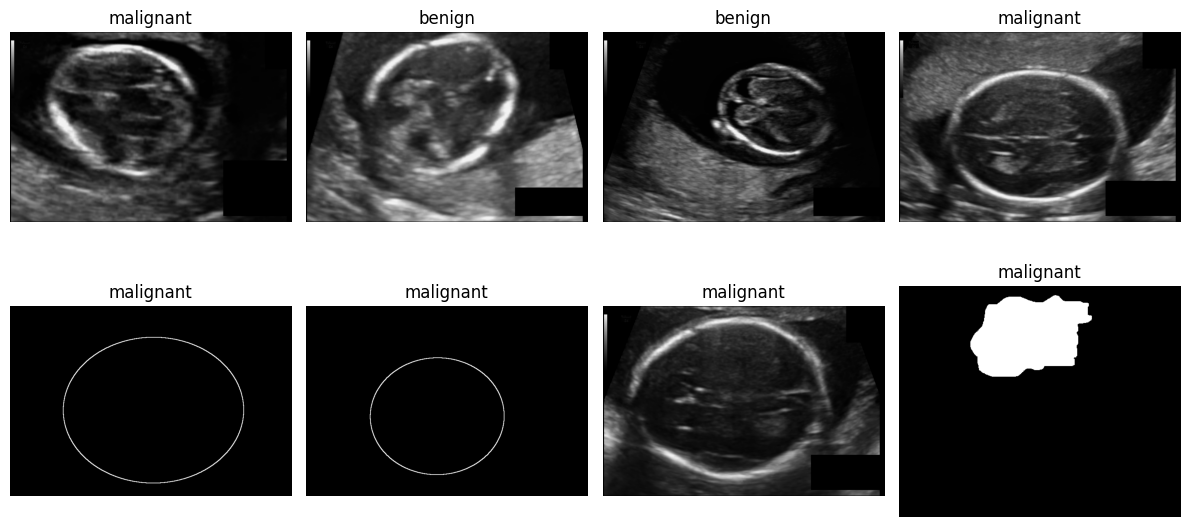

In [ ]:
from PIL import Image

VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
records = []
for label in ["benign", "malignant"]:
    folder = data_dir / label
    for p in folder.rglob("*"):
        if p.is_file() and p.suffix.lower() in VALID_EXTS:
            records.append({"path": str(p), "label": label})

df = pd.DataFrame(records).drop_duplicates("path").reset_index(drop=True)
if df.empty:
    raise ValueError("No supported image files found in benign/malignant folders.")

print(df["label"].value_counts())
display(df.head())

# Show a few samples
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, df.sample(min(8, len(df)), random_state=SEED).iterrows()):
    im = Image.open(row["path"]).convert("RGB")
    ax.imshow(im)
    ax.set_title(row["label"])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Make train, validation, and test splits



In [ ]:
from sklearn.model_selection import StratifiedGroupKFold


df["group_id"] = df["path"].map(lambda s: Path(s).stem.split("_")[0])

# 5-fold stratified group split: one fold test, one fold validation, remaining folds train.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(sgkf.split(df["path"], df["label"], groups=df["group_id"]))
trainval_idx, test_idx = None, None
# Choose the fold with the class distribution closest to the overall distribution.
overall = df["label"].value_counts(normalize=True).to_dict()
def distribution_error(frame, idx):
    d = frame.iloc[idx]["label"].value_counts(normalize=True).to_dict()
    return sum(abs(d.get(k, 0) - v) for k, v in overall.items())
test_fold = min(range(len(splits)), key=lambda i: distribution_error(df, splits[i][1]))
trainval_idx, test_idx = splits[test_fold]
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Split the remaining data into train and validation, again group-aware.
sgkf2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
inner_splits = list(sgkf2.split(trainval_df["path"], trainval_df["label"], groups=trainval_df["group_id"]))
val_fold = min(range(len(inner_splits)), key=lambda i: distribution_error(trainval_df, inner_splits[i][1]))
train_idx, val_idx = inner_splits[val_fold]
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name}: n={len(part)}")
    print(part["label"].value_counts())
print("\nGroup overlap checks:")
print("train/test overlap:", len(set(train_df.group_id) & set(test_df.group_id)))
print("validation/test overlap:", len(set(val_df.group_id) & set(test_df.group_id)))
assert not (set(train_df.group_id) & set(test_df.group_id))
assert not (set(val_df.group_id) & set(test_df.group_id))

# Save exact split lists for reproducibility.
split_dir = Path("model_outputs")
split_dir.mkdir(exist_ok=True)
train_df.to_csv(split_dir / "train_split.csv", index=False)
val_df.to_csv(split_dir / "validation_split.csv", index=False)
test_df.to_csv(split_dir / "test_split.csv", index=False)



Train: n=1558
label
malignant    1325
benign        233
Name: count, dtype: int64

Validation: n=524
label
malignant    445
benign        79
Name: count, dtype: int64

Test: n=517
label
malignant    439
benign        78
Name: count, dtype: int64

Group overlap checks:
train/test overlap: 0
validation/test overlap: 0


## 4. Baseline model: HOG features + class-weighted SVM

In [ ]:
from skimage.feature import hog
from skimage.color import rgb2gray
from skimage.transform import resize
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    balanced_accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

LABEL_TO_INT = {"benign": 0, "malignant": 1}
IMG_SIZE = (128, 128)

def hog_features(paths):
    feats = []
    for path in paths:
        image = Image.open(path).convert("RGB")
        arr = np.asarray(image)
        arr = resize(arr, (*IMG_SIZE, 3), anti_aliasing=True, preserve_range=True).astype(np.uint8)
        gray = rgb2gray(arr)
        feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), block_norm="L2-Hys")
        feats.append(feat)
    return np.asarray(feats, dtype=np.float32)

X_train_hog = hog_features(train_df["path"])
X_val_hog = hog_features(val_df["path"])
X_test_hog = hog_features(test_df["path"])
y_train = train_df["label"].map(LABEL_TO_INT).to_numpy()
y_val = val_df["label"].map(LABEL_TO_INT).to_numpy()
y_test = test_df["label"].map(LABEL_TO_INT).to_numpy()

baseline = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC(C=3, kernel="rbf", class_weight="balanced", probability=True,
                random_state=SEED))
])
baseline.fit(X_train_hog, y_train)

baseline_val_prob = baseline.predict_proba(X_val_hog)[:, 1]
baseline_val_pred = (baseline_val_prob >= 0.5).astype(int)
print("Baseline validation report (not test):")
print(classification_report(y_val, baseline_val_pred, target_names=["benign", "malignant"], zero_division=0))


Baseline validation report (not test):
              precision    recall  f1-score   support

      benign       0.55      0.08      0.13        79
   malignant       0.86      0.99      0.92       445

    accuracy                           0.85       524
   macro avg       0.70      0.53      0.53       524
weighted avg       0.81      0.85      0.80       524



## 5. Improved model: transfer learning with MobileNetV2

MobileNetV2 starts from ImageNet-pretrained features, then fine-tunes the top layers for the binary ultrasound task. The class weights address imbalance. This model may require internet access the first time to download pretrained weights; run on Colab GPU if possible.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

IMG_SHAPE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.image.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SHAPE)
    image = tf.cast(image, tf.float32)  # MobileNetV2 preprocess_input expects 0..255
    label = tf.cast(label, tf.float32)
    return image, label

def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).to_numpy()
    labels = frame["label"].map(LABEL_TO_INT).astype(np.int32).to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        aug = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.10),
            layers.RandomContrast(0.10),
        ])
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Compute class weights from training data only.
counts = train_df["label"].map(LABEL_TO_INT).value_counts().to_dict()
total = sum(counts.values())
class_weight = {
    cls: total / (2 * counts.get(cls, 1))
    for cls in [0, 1]
}
print("Class weights:", class_weight)

base = keras.applications.MobileNetV2(
    input_shape=(*IMG_SHAPE, 3), include_top=False, weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=(*IMG_SHAPE, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
improved = keras.Model(inputs, outputs)

improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2,
                                     min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("model_outputs/mobilenet_best.keras",
                                    monitor="val_pr_auc", mode="max",
                                    save_best_only=True, verbose=1)
]

history1 = improved.fit(
    train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weight, callbacks=callbacks, verbose=1
)


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Class weights: {0: 3.3433476394849784, 1: 0.5879245283018868}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.6269 - loss: 0.6870 - pr_auc: 0.9235 - roc_auc: 0.7130
Epoch 1: val_pr_auc improved from None to 0.96705, saving model to model_outputs/mobilenet_best.keras

Epoch 1: finished saving model to model_outputs/mobilenet_best.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 60s 469ms/step - accuracy: 0.6669 - loss: 0.6004 - pr_auc: 0.9512 - roc_auc: 0.7544 - val_accuracy: 0.6279 - val_loss: 0.5321 - val_pr_auc: 0.9670 - val_roc_auc: 0.8262 - learning_rate: 0.0010
Epoch 2/15
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.6613 - loss: 0.5430 - pr_auc: 0.9594 - roc_auc: 0.7871
Epoch 2: val_pr_auc did not improve from 0.96705
98/98 ━━━━━━━━━━━━━━━━━━━━ 23s 232ms/step - accuracy: 0.6733 - loss: 0.5376 - pr_auc: 0.9596 - roc_auc: 0.7

## 6. Fine-tune the top part of the pretrained network

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.7043 - loss: 0.4504 - pr_auc: 0.9686 - roc_auc: 0.8304
Epoch 1: val_pr_auc did not improve from 0.96790
98/98 ━━━━━━━━━━━━━━━━━━━━ 48s 354ms/step - accuracy: 0.6945 - loss: 0.4682 - pr_auc: 0.9661 - roc_auc: 0.8207 - val_accuracy: 0.6088 - val_loss: 0.5759 - val_pr_auc: 0.9666 - val_roc_auc: 0.8241 - learning_rate: 1.0000e-05
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.6792 - loss: 0.4316 - pr_auc: 0.9698 - roc_auc: 0.8508
Epoch 2: val_pr_auc did not improve from 0.96790
98/98 ━━━━━━━━━━━━━━━━━━━━ 62s 239ms/step - accuracy: 0.6733 - loss: 0.4364 - pr_auc: 0.9694 - roc_auc: 0.8381 - val_accuracy: 0.6336 - val_loss: 0.4677 - val_pr_auc: 0.9642 - val_roc_auc: 0.8124 - learning_rate: 1.0000e-05
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.6659 - loss: 0.4531 - pr_auc: 0.9658 - roc_auc: 0.8223
Epoch 3: val_pr_auc did not improve from 0.96790
98/98 ━━━━━━━━━━━━━━━━━━━━ 23s 234ms/step 

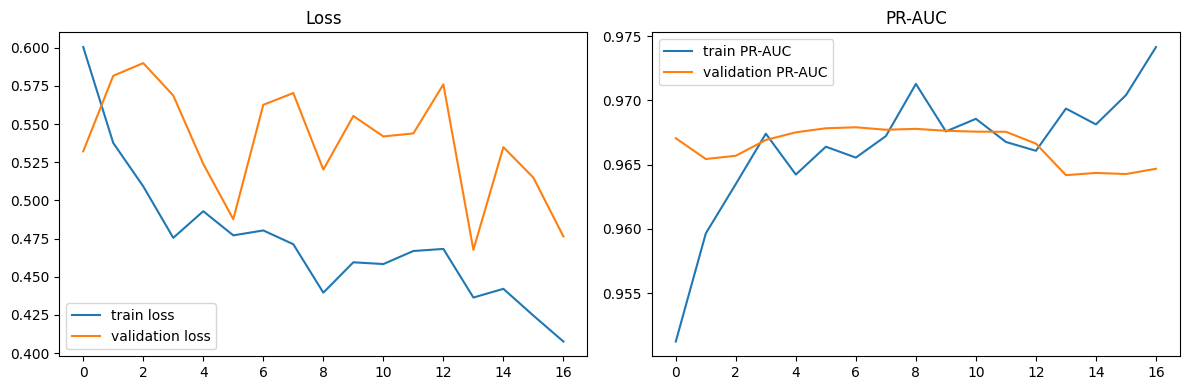

In [ ]:
# Fine-tune only the final portion of MobileNetV2; keep BatchNorm layers frozen.
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history2 = improved.fit(
    train_ds, validation_data=val_ds, epochs=10,
    class_weight=class_weight, callbacks=callbacks, verbose=1
)

# Plot learning curves (training/validation only)
hist = {}
for h in [history1, history2]:
    for k, vals in h.history.items():
        hist.setdefault(k, []).extend(vals)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.get("loss", []), label="train loss")
axes[0].plot(hist.get("val_loss", []), label="validation loss")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(hist.get("pr_auc", []), label="train PR-AUC")
axes[1].plot(hist.get("val_pr_auc", []), label="validation PR-AUC")
axes[1].set_title("PR-AUC"); axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Evaluate both models on the same held-out test set

The test set is used only here, after training and model selection. The positive class is **malignant**. Recall/sensitivity for malignant images is particularly important; specificity measures how well benign images are recognized.

33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 181ms/step


,Model,Threshold,Accuracy,Balanced accuracy,Precision (malignant),Recall / Sensitivity (malignant),Specificity (benign),F1 (malignant),ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Baseline: HOG + SVM,0.5,0.8491,0.5422,0.8603,0.9818,0.1026,0.9170,0.7660,0.9541,8,70,8,431
1,Improved: MobileNetV2 fine-tuned,0.5,0.6228,0.7726,0.9959,0.5581,0.9872,0.7153,0.8261,0.9670,77,1,194,245



 Baseline: HOG + SVM
              precision    recall  f1-score   support

      benign       0.50      0.10      0.17        78
   malignant       0.86      0.98      0.92       439

    accuracy                           0.85       517
   macro avg       0.68      0.54      0.54       517
weighted avg       0.81      0.85      0.80       517



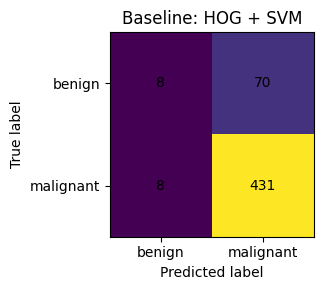


 Improved: MobileNetV2 fine-tuned
              precision    recall  f1-score   support

      benign       0.28      0.99      0.44        78
   malignant       1.00      0.56      0.72       439

    accuracy                           0.62       517
   macro avg       0.64      0.77      0.58       517
weighted avg       0.89      0.62      0.67       517



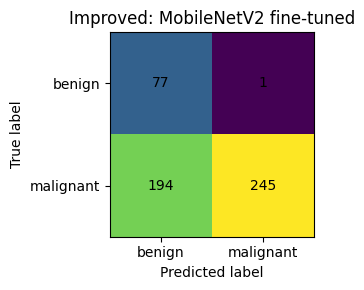

In [ ]:
def metric_row(y_true, prob, model_name, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Precision (malignant)": precision_score(y_true, pred, zero_division=0),
        "Recall / Sensitivity (malignant)": recall_score(y_true, pred, zero_division=0),
        "Specificity (benign)": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1 (malignant)": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        "PR-AUC": average_precision_score(y_true, prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

# Baseline predictions on the test set
baseline_test_prob = baseline.predict_proba(X_test_hog)[:, 1]

# Deep model predictions on the exact same test images in test_df order
improved_test_prob = improved.predict(test_ds, verbose=1).ravel()

results = pd.DataFrame([
    metric_row(y_test, baseline_test_prob, "Baseline: HOG + SVM"),
    metric_row(y_test, improved_test_prob, "Improved: MobileNetV2 fine-tuned")
])
display(results.round(4))

for name, prob in [
    ("Baseline: HOG + SVM", baseline_test_prob),
    ("Improved: MobileNetV2 fine-tuned", improved_test_prob)
]:
    pred = (prob >= 0.5).astype(int)
    print("\n", name)
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=["benign", "malignant"], zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4, 3))
    im = ax.imshow(cm)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], ["benign", "malignant"])
    ax.set_yticks([0, 1], ["benign", "malignant"])
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, str(val), ha="center", va="center")
    plt.tight_layout()
    plt.show()


## 8. Statistical uncertainty: bootstrap confidence intervals

In [ ]:
# Bootstrap confidence intervals for test metrics.
# This quantifies uncertainty from this finite test sample; it does not fix dataset bias.
from sklearn.metrics import f1_score

def bootstrap_ci(y_true, prob, metric_fn, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = []
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        try:
            values.append(metric_fn(y_true[idx], prob[idx]))
        except Exception:
            continue
    return np.quantile(values, [0.025, 0.975])

metric_fns = {
    "Accuracy": lambda y, p: accuracy_score(y, p >= 0.5),
    "F1 (malignant)": lambda y, p: f1_score(y, p >= 0.5, zero_division=0),
    "ROC-AUC": lambda y, p: roc_auc_score(y, p),
    "PR-AUC": lambda y, p: average_precision_score(y, p),
}
ci_rows = []
for model_name, probs in [
    ("Baseline: HOG + SVM", baseline_test_prob),
    ("Improved: MobileNetV2 fine-tuned", improved_test_prob)
]:
    for metric_name, fn in metric_fns.items():
        lo, hi = bootstrap_ci(y_test, probs, fn)
        ci_rows.append({"Model": model_name, "Metric": metric_name,
                        "95% CI lower": lo, "95% CI upper": hi})
ci_df = pd.DataFrame(ci_rows)
display(ci_df.round(4))


,Model,Metric,95% CI lower,95% CI upper
0,Baseline: HOG + SVM,Accuracy,0.8182,0.8782
1,Baseline: HOG + SVM,F1 (malignant),0.8987,0.9346
2,Baseline: HOG + SVM,ROC-AUC,0.7185,0.8102
3,Baseline: HOG + SVM,PR-AUC,0.9397,0.9673
4,Improved: MobileNetV2 fine-tuned,Accuracy,0.5822,0.6654
5,Improved: MobileNetV2 fine-tuned,F1 (malignant),0.6775,0.7525
6,Improved: MobileNetV2 fine-tuned,ROC-AUC,0.7840,0.8648
7,Improved: MobileNetV2 fine-tuned,PR-AUC,0.9556,0.9772


## 9. Paired comparison on the same test cases

McNemar's test compares whether the models make different errors on the same examples. It tests error disagreement, not whether every metric is better. Interpret p-values alongside the effect size and confidence intervals.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

base_pred = (baseline_test_prob >= 0.5).astype(int)
deep_pred = (improved_test_prob >= 0.5).astype(int)

base_correct = base_pred == y_test
deep_correct = deep_pred == y_test

# b: baseline wrong/deep model right; c: baseline right/deep model wrong
b = int(np.sum((~base_correct) & deep_correct))
c = int(np.sum(base_correct & (~deep_correct)))
table = [[int(np.sum(base_correct & deep_correct)), c],
         [b, int(np.sum((~base_correct) & (~deep_correct)))]]
test_result = mcnemar(table, exact=False, correction=True)

print("Paired correctness table [[both correct, baseline only correct],")
print("                         [deep only correct, both wrong]]:")
print(table)
print(f"McNemar statistic = {test_result.statistic:.4f}")
print(f"McNemar p-value = {test_result.pvalue:.6f}")
print(f"Accuracy difference (improved - baseline) = "
      f"{accuracy_score(y_test, deep_pred) - accuracy_score(y_test, base_pred):.4f}")

if test_result.pvalue < 0.05:
    print("At alpha=0.05, error patterns differ significantly between models.")
else:
    print("At alpha=0.05, there is not enough evidence that error patterns differ.")
print("This does not prove clinical usefulness; examine malignant recall, false negatives,")
print("confidence intervals, and external validation.")


Paired correctness table [[both correct, baseline only correct],
                         [deep only correct, both wrong]]:
[[250, 189], [72, 6]]
McNemar statistic = 51.5556
McNemar p-value = 0.000000
Accuracy difference (improved - baseline) = -0.2263
At alpha=0.05, error patterns differ significantly between models.
This does not prove clinical usefulness; examine malignant recall, false negatives,
confidence intervals, and external validation.


## 10. Save models, predictions, and results

In [ ]:
# Save the baseline and final deep-learning model.
import joblib
joblib.dump(baseline, "model_outputs/baseline_hog_svm.joblib")
improved.save("model_outputs/improved_mobilenetv2.keras")

predictions = test_df[["path", "label"]].copy()
predictions["y_true"] = y_test
predictions["baseline_probability_malignant"] = baseline_test_prob
predictions["improved_probability_malignant"] = improved_test_prob
predictions.to_csv("model_outputs/test_predictions.csv", index=False)
results.to_csv("model_outputs/test_metrics.csv", index=False)
ci_df.to_csv("model_outputs/bootstrap_confidence_intervals.csv", index=False)

print("Saved artifacts in:", Path("model_outputs").resolve())
print("Files:", sorted(p.name for p in Path("model_outputs").iterdir()))


Saved artifacts in: /content/model_outputs
Files: ['baseline_hog_svm.joblib', 'bootstrap_confidence_intervals.csv', 'improved_mobilenetv2.keras', 'mobilenet_best.keras', 'test_metrics.csv', 'test_predictions.csv', 'test_split.csv', 'train_split.csv', 'validation_split.csv']


## How to write the conclusion

Use the values printed by the notebook; do not claim a model is better based on accuracy alone.

- State the fixed train/validation/test split and confirm both models used the same test images.
- Compare accuracy, balanced accuracy, malignant precision/recall, specificity, F1, ROC-AUC and PR-AUC.
- Include the 95% bootstrap confidence intervals and McNemar p-value.
- If the improved model's metrics are higher but intervals overlap or the paired test is not significant, describe the evidence as inconclusive rather than claiming a proven improvement.
- The dataset is imbalanced and may contain multiple images from the same patient. Grouping is only as reliable as the filename convention. Confirm patient-level identifiers, use external validation, and do not use this notebook for clinical diagnosis.